In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans,DBSCAN
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [ ]:
import kagglehub

path = kagglehub.dataset_download("carrie1/ecommerce-data")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ecommerce-data' dataset.
Path to dataset files: /kaggle/input/ecommerce-data


In [ ]:
import os
import glob
csv_files = glob.glob(path + "/**/*.csv", recursive=True)

In [ ]:
print("Files found:", csv_files)
df = pd.read_csv(csv_files[0], encoding="ISO-8859-1")
print("Dataset shape:", df.shape)
display(df.head())

Files found: ['/kaggle/input/ecommerce-data/data.csv']
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [ ]:
df.shape

(541909, 8)

In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [ ]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
df.dropna(subset=['CustomerID'], inplace=True)

In [ ]:
df.drop_duplicates()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [ ]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")].copy()

In [ ]:
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

In [ ]:
df["CustomerID"] = df["CustomerID"].astype(int)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])


In [ ]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [ ]:
print("Cleaned dataset shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())

Cleaned dataset shape: (397884, 9)
Unique customers: 4338


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [ ]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

In [ ]:
rfm=df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",lambda x:(reference_date-x.max()).days),
    Frequency=("InvoiceNo","count"),
    Monetary=("TotalPrice","sum")
)

print("No. of customers:-",len(rfm))
rfm.head()
rfm.describe()

No. of customers:- 4338


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,91.720609,2054.266460
std,100.014169,228.785094,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,17.000000,307.415000
50%,51.000000,41.000000,674.485000
75%,142.000000,100.000000,1661.740000
max,374.000000,7847.000000,280206.020000


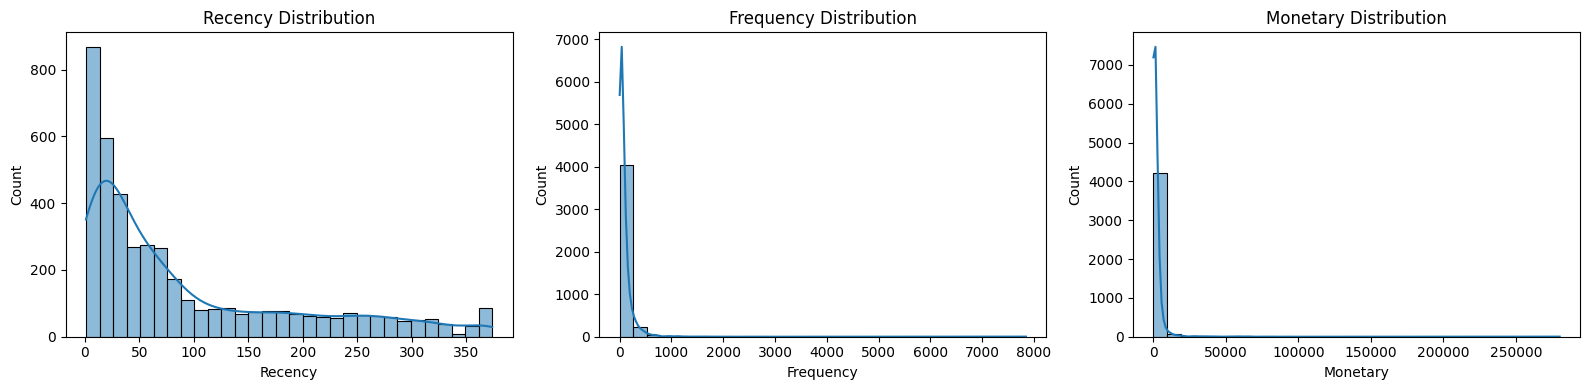

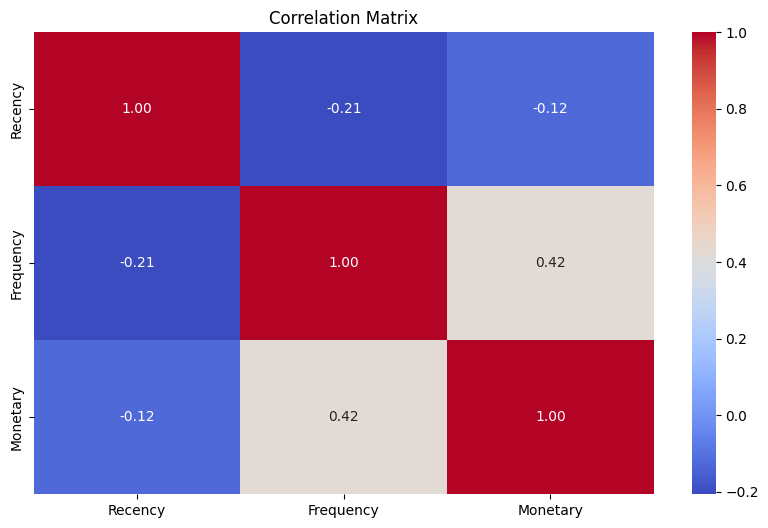

In [ ]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,col in zip(axes,["Recency","Frequency","Monetary"]):
  sns.histplot(data=rfm,x=col,bins=30,kde=True,ax=ax)
  ax.set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10,6))
sns.heatmap(rfm.corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
rfm_features=rfm[["Recency","Frequency","Monetary"]].copy()
x_log = np.log1p(rfm_features)

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_log)

print("Scaled data shape:", x_scaled.shape)
print("Means:", x_scaled.mean(axis=0).round(4))
print("Standard deviations:", x_scaled.std(axis=0).round(4))

Scaled data shape: (4338, 3)
Means: [-0. -0.  0.]
Standard deviations: [1. 1. 1.]


In [ ]:
pca = PCA(n_components=2, random_state=42)
x_pca = pca.fit_transform(x_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total variance retained:",
      round(pca.explained_variance_ratio_.sum(), 4))

Explained variance ratio: [0.7246 0.1968]
Total variance retained: 0.9214


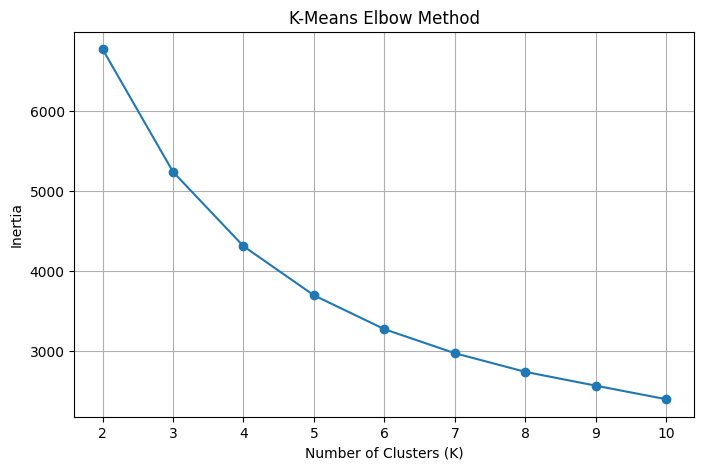

In [ ]:
inertias = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(x_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm["KMeans_Cluster"] = kmeans.fit_predict(x_scaled)

print("K-Means cluster counts:")
print(rfm["KMeans_Cluster"].value_counts().sort_index())

if rfm["KMeans_Cluster"].nunique() > 1:
    score = silhouette_score(
        x_scaled,
        rfm["KMeans_Cluster"],
        sample_size=min(5000, len(rfm)),
        random_state=42
    )
    print("K-Means silhouette score:", round(score, 4))

K-Means cluster counts:
KMeans_Cluster
0    1377
1     872
2     868
3    1221
Name: count, dtype: int64
K-Means silhouette score: 0.3085


In [ ]:
dbscan = DBSCAN(eps=0.5, min_samples=10)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(x_scaled)

labels = rfm["DBSCAN_Cluster"]
n_clusters = len(set(labels) - {-1})
n_noise = int((labels == -1).sum())

print("DBSCAN cluster counts:")
print(labels.value_counts().sort_index())
print("Number of clusters excluding noise:", n_clusters)
print("Number of noise customers:", n_noise)

non_noise = labels != -1
if len(set(labels[non_noise])) >= 2 and non_noise.sum() > 2:
    print(
        "DBSCAN silhouette score (excluding noise):",
        round(silhouette_score(X_scaled[non_noise], labels[non_noise]), 4)
    )
else:
    print("Silhouette score unavailable: DBSCAN did not find enough usable clusters.")

DBSCAN cluster counts:
DBSCAN_Cluster
-1     115
 0    4223
Name: count, dtype: int64
Number of clusters excluding noise: 1
Number of noise customers: 115
Silhouette score unavailable: DBSCAN did not find enough usable clusters.


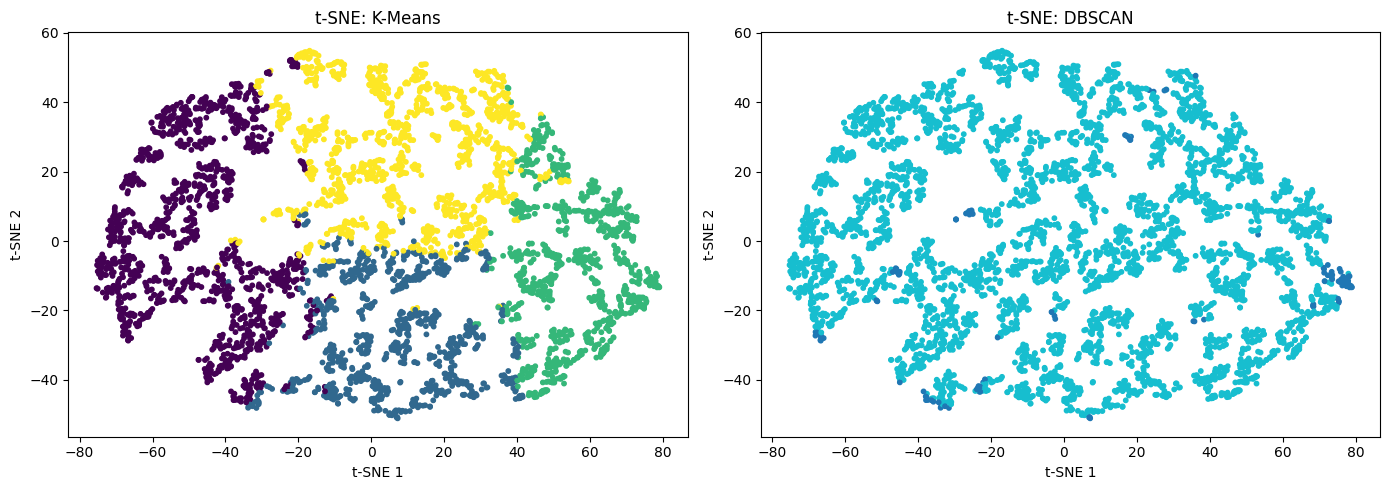

In [ ]:
perplexity = min(30, max(2, (len(rfm) - 1) // 3))

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=perplexity,
    init="pca",
    learning_rate="auto"
)

X_tsne = tsne.fit_transform(x_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=rfm["KMeans_Cluster"], cmap="viridis", s=10
)
axes[0].set_title("t-SNE: K-Means")
axes[0].set_xlabel("t-SNE 1")
axes[0].set_ylabel("t-SNE 2")

axes[1].scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=rfm["DBSCAN_Cluster"], cmap="tab10", s=10
)
axes[1].set_title("t-SNE: DBSCAN")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

In [ ]:
kmeans_profile = rfm.groupby("KMeans_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(kmeans_profile)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
KMeans_Cluster,,,,
0,1377,185.29,14.97,298.59
1,872,19.89,38.74,612.06
2,868,12.96,282.89,7042.57
3,1221,96.38,80.21,1518.09


In [ ]:
recency_mid = rfm["Recency"].median()
frequency_mid = rfm["Frequency"].median()
monetary_mid = rfm["Monetary"].median()

def assign_persona(row):
    recent = row["Avg_Recency"] <= recency_mid
    frequent = row["Avg_Frequency"] >= frequency_mid
    high_value = row["Avg_Monetary"] >= monetary_mid

    if recent and frequent and high_value:
        return "Loyal VIP Customers"
    elif recent and high_value:
        return "Big Spenders"
    elif recent and frequent:
        return "Active Loyal Customers"
    elif not recent and high_value:
        return "At-Risk Valuable Customers"
    elif not recent and not frequent and not high_value:
        return "Dormant Customers"
    else:
        return "Regular Customers"

kmeans_profile["Persona"] = kmeans_profile.apply(assign_persona, axis=1)

marketing_actions = {
    "Loyal VIP Customers": "Offer loyalty rewards and exclusive benefits.",
    "Big Spenders": "Recommend premium products and cross-sell.",
    "Active Loyal Customers": "Provide loyalty points and repeat-purchase offers.",
    "At-Risk Valuable Customers": "Send personalized win-back offers.",
    "Dormant Customers": "Use targeted reactivation campaigns.",
    "Regular Customers": "Encourage repeat purchases with recommendations."
}

kmeans_profile["Marketing_Action"] = kmeans_profile["Persona"].map(
    marketing_actions
)

display(kmeans_profile)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Persona,Marketing_Action
KMeans_Cluster,,,,,,
0,1377,185.29,14.97,298.59,Dormant Customers,Use targeted reactivation campaigns.
1,872,19.89,38.74,612.06,Regular Customers,Encourage repeat purchases with recommendations.
2,868,12.96,282.89,7042.57,Loyal VIP Customers,Offer loyalty rewards and exclusive benefits.
3,1221,96.38,80.21,1518.09,At-Risk Valuable Customers,Send personalized win-back offers.


In [ ]:
dbscan_profile = rfm.groupby("DBSCAN_Cluster").agg(
    Customers=("Recency", "size"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

display(dbscan_profile)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary
DBSCAN_Cluster,,,,
-1,115,62.41,439.81,25676.08
0,4223,93.36,82.24,1411.00


In [ ]:

results = rfm.copy()

results["PCA_1"] = x_pca[:, 0]
results["PCA_2"] = x_pca[:, 1]
results["TSNE_1"] = X_tsne[:, 0]
results["TSNE_2"] = X_tsne[:, 1]

results.to_csv("customer_segments.csv", index=True)
kmeans_profile.to_csv("kmeans_cluster_profiles.csv")
dbscan_profile.to_csv("dbscan_cluster_profiles.csv")

print("All results exported successfully!")

All results exported successfully!


In [ ]:
from google.colab import files

files.download("customer_segments.csv")
files.download("kmeans_cluster_profiles.csv")
files.download("dbscan_cluster_profiles.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>